# Case Study 14 — One Credit Model or Many? Segment-Specific Underwriting, the Top/Bottom Bad-Rate Ratio, and When Segmentation Stops Paying

**Priority:** ★★ Good to have · **Reference:** Case Study 14 — *Kissht (OnEMI): segment-specific underwriting with 39 sub-models* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Chief Risk Officer, Head of Credit Policy, Model Risk Management, Business heads (consumer durable & personal loans)
**Data:** ⚠️ **SYNTHETIC** (D-14-01). Lender data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs14_segmented_underwriting.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Kissht's documented design; the source figures are inconsistent and come from RHP analyses. Written after the analysis.)*

- **The question:** should a digital lender run one credit model, a handful of segment models, or dozens of sub-models?
- **Risk drivers really do differ by segment** (likelihood-ratio test χ² = 1,168, p ≈ 1e-238):
  - The bureau score counts twice as much for thick files as for thin ones.
  - Bounced payments matter a lot for new-to-credit and thin-file borrowers, and not at all for thick files.
  - Income volatility matters 2–4× more for the self-employed.
- **But a single well-built global model captures most of that.** Out-of-time AUCs:

| Model | AUC |
|---|---|
| Bureau score alone | 0.678 |
| Global logistic | 0.847 |
| **Global gradient boosting** | **0.854** |
| **12 segmented logistic models** | **0.857** |
| 12 segmented gradient-boosting models | 0.834 (worse) |

  - The two best are statistically tied for business purposes: at a 3% bad-rate target they approve **86.2% vs 86.0%** of applicants, vs 84.9% for the global logistic.
- **Fragmentation backfires:** splitting into 2 → 12 segments helps a little (AUC 0.847 → 0.857). At 24 segments the gain flattens, and at **72 segments it is gone** (0.847), because the smallest segments have only 3–47 defaults to learn from. Kissht's "39 sub-models" is at the edge of what the data can support unless its book is far larger.
- **"5.17× vs 2.13×" is not a fair comparison on its own.** The top/bottom bad-rate ratio of the same model ranges from **36× (quintiles) to 70× (deciles) to infinity (ventiles)**. The bureau score's ratio nearly doubles when NTC borrowers, whom it cannot score, are excluded. Our best model's decile ratio is 2.9× the bureau's, in the same spirit as the documented 2.4×, but only meaningful with the bucket definition and population stated.
- **₹ impact (1 lakh applicants/month):**
  - The best models add ≈ **₹3.2 crore/year** of profit over the global logistic at the same 3% loss rate.
  - Compared with scoring on the bureau alone, any of the models is worth more than ₹100 crore/year, because the bureau cannot score 30% of applicants.
- **I recommend:** a **global gradient-boosting model plus a separate repeat-customer model** (2 models, not 39), or at most ~6–12 logistic segments where model-risk teams require scorecards. Validate every segment for events-per-variable ≥ 10, calibration and rank ordering. Report KS/Gini and approval-at-fixed-loss next to any top/bottom ratio.

## 1. The Problem in Simple English

A digital lender approves small loans in minutes for very different people:
- A salaried person with ten years of credit history.
- A first-time borrower with no bureau record at all ("new to credit").
- A self-employed shopkeeper whose income swings month to month.
- A repeat customer who has already repaid two loans.

**What predicts default is different for each.** The bureau score is everything for the first person and does not exist for the second. Kissht reportedly runs **39 specialised sub-models** for this reason, and claims its scores separate the riskiest from the safest customers **5.17×** (vs 2.13× for bureau scores).

Leaders need to know:
- Do separate models really beat one well-built global model?
- How many segments are too many?
- Is "5.17× vs 2.13×" a fair way to compare models?

## 2. Reference from the Case File

### (a) What Kissht did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Underwrite very different customer types quickly and keep losses controlled" |
| Data | "over 400" key variables (bureau, KYC, banking/transactional, digital footprint); feature library "over 7,000 variables" (75% credit/financial, 25% consumption/online); "200+ fraud triggers" |
| Approach | Segment-specific models: "**39 specialized ML sub-models**" (MoneyFlow) or "40+ underwriting models" (Zen Nivesh); algorithms ND |
| Statistics | "approximately **5.17x** separation in default rates between highest and lowest risk segments" vs "**2.13x** for traditional credit bureau scores"; Zen Nivesh: "2.5x better risk separation". **The sources are inconsistent**; KS/Gini ND |
| Decision | ≈ **85%** of new customers get offers within 10 minutes; "**26.46%** of repeat applicants were declined" |
| Impact (9M FY26) | GNPA 2.90%; NNPA 0.38%; 30-DPD collection efficiency 96.95% |

**Sources:** MoneyFlow India, 5 May 2026 — https://moneyflowindia.substack.com/p/moneyflow-india-deep-dive-2-kissht · Zen Nivesh, 17 Jul 2026 — https://zennivesh.substack.com/p/onemi-tech-kissht-an-emi-factory (both are independent analyses of the RHP; check the RHP for exact figures)

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 120,000 booked loans over 12 months; 12 structural segments (new-to-credit / thin / thick bureau × salaried / self-employed × new / repeat customer); 2 products; 17 features. **Default drivers differ by segment by construction.** Target: 60+ DPD within 6 months (≈ 7%). |
| Statistics added | Likelihood-ratio (Chow-type) test that coefficients differ by segment; global vs segmented models out-of-time with DeLong; KS/Gini; the **top/bottom bad-rate ratio** with bootstrap CIs and its sensitivity to bucket choice; a **number-of-segments sweep** (1 → 48 sub-models) with events-per-variable; per-segment calibration; Cochran–Armitage rank-ordering trend; PSI for mix shift; approval rate at a fixed loss target |

### (c) How the industry uses this

Segmented scorecards are the oldest practice in retail credit (FICO's "scorecard trees"). In India, every digital lender separates **NTC vs bureau-tested** and **new vs repeat** customers (KreditBee, MoneyView, Fibe, Kissht, Bajaj Finance). Bureaus themselves (CIBIL, CRIF, Experian) ship separate NTC scores. The open question is always **how far to split**, because every extra sub-model must be validated, monitored and documented under RBI's model-risk expectations.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we run one global credit model, a handful of segment models, or dozens of sub-models? |
| Analytical | (1) Do risk drivers differ between segments? (2) Do segmented models rank and price risk better **out-of-time** than a global model? (3) At what number of segments does performance stop improving? |

**Hypotheses**
- **H1 (heterogeneity):** H0: logistic coefficients are the same in all segments (LR test of segment × feature interactions).
- **H2 (segmented vs global):** H0: AUC(segmented) = AUC(global) on out-of-time loans (DeLong, Holm across model pairs).
- **H3 (fragmentation):** H0: AUC does not decline as the number of segments rises beyond the optimum (reported with bootstrap CIs; descriptive).
- **H4 (calibration):** H0: predicted = observed bad rate within each segment (calibration-in-the-large, z-test; Holm across 12 segments).

**Primary metric:** out-of-time AUC/Gini and **approval rate at a fixed portfolio bad rate** (the business lever). **Communication metric:** top/bottom decile bad-rate ratio (the documented style). **Guardrail:** per-segment calibration error ≤ 1 pp. **Design:** train months 1–9 → **test months 10–12**.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian loan-performance data with bureau depth and bank-statement features | **None.** The RBI/CIC data are confidential. UCI Taiwan default (credit cards) and German Credit have no NTC/thin/thick structure and no bank-statement features. Lending Club (US, Kaggle-hosted) is excluded by the brief. |
| **Decision** | Synthetic booked loans with segment-specific default drivers (D-14-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs14.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 14 (Kissht-style segment-specific underwriting)
=====================================================================================
THIS DATA IS SYNTHETIC. Lender application and performance data are confidential.

12 months of disbursed small-ticket loans (consumer-durable EMI and short personal loans). Applicants
fall into structurally different segments:
  bureau depth   : NTC (new to credit, no bureau score) / THIN (1-2 tradelines) / THICK
  employment     : salaried / self-employed
  relationship   : new customer / repeat customer (has prior loans with the lender)
What drives default DIFFERS by segment (the reason to segment):
  * THICK file: bureau score and recent delinquencies dominate
  * NTC / THIN: bank-statement cash-flow (inflow, volatility, bounces) and digital footprint matter
  * self-employed: inflow volatility and GST-turnover consistency matter more than for salaried
  * repeat: own repayment history with the lender dominates everything else
Target: bad = 60+ DPD within 6 months on book. A traditional bureau score exists for THIN/THICK only.

Calibration anchors (reference file, Case Study 14): "39 specialized ML sub-models" / "40+ models";
"~5.17x separation in default rates between highest and lowest risk segments" vs "2.13x for traditional
credit bureau scores"; GNPA 2.90%; ~85% of new customers get offers in 10 minutes; 26.46% of repeat
applicants declined. Rates are our assumptions (decision.md D-14-02). Hidden truth columns start "_".

Output: data/cs14/loans.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
START = pd.Timestamp("2025-04-01")


def generate(seed=SEED, n=120_000):
    rng = np.random.default_rng(seed)
    month = rng.integers(0, 12, n)
    depth = rng.choice(["NTC", "THIN", "THICK"], n, p=[0.30, 0.25, 0.45])
    emp = rng.choice(["salaried", "self_employed"], n, p=[0.62, 0.38])
    repeat = (rng.random(n) < np.where(month < 3, 0.15, 0.32)).astype(int)        # repeat share grows over the year (mix shift)
    product = rng.choice(["consumer_durable", "personal_loan"], n, p=[0.55, 0.45])
    age = np.clip(rng.normal(31, 7, n), 21, 60).round()
    city_tier = rng.choice([1, 2, 3], n, p=[0.35, 0.40, 0.25])
    income = np.exp(rng.normal(np.log(np.where(emp == "salaried", 32000, 28000)), 0.45))
    # latent creditworthiness (unobserved) drives everything a little
    z = rng.normal(0, 1, n)
    # bureau
    bureau = np.where(depth == "NTC", np.nan, np.clip(np.round(720 + 55 * z + rng.normal(0, 40, n) - 25 * (depth == "THIN")), 300, 900))
    n_trades = np.where(depth == "NTC", 0, np.where(depth == "THIN", rng.integers(1, 3, n), rng.integers(3, 15, n)))
    dpd30_12m = np.where(depth == "THICK", rng.poisson(np.exp(-1.2 - 0.6 * z)), np.where(depth == "THIN", rng.poisson(np.exp(-1.8 - 0.4 * z)), 0))
    enquiries_3m = rng.poisson(np.exp(0.4 - 0.25 * z + 0.3 * (depth != "NTC")))
    # bank statement / cash flow
    inflow_vol = np.clip(rng.gamma(2, 0.12, n) * np.where(emp == "self_employed", 1.8, 1.0) * np.exp(-0.2 * z), 0.02, 2.5)
    bounces_6m = rng.poisson(np.exp(-1.5 - 0.7 * z + 0.4 * (emp == "self_employed")))
    avg_bal_to_income = np.clip(np.exp(rng.normal(-1.2 + 0.35 * z, 0.6)), 0.01, 5)
    gst_consistency = np.where(emp == "self_employed", np.clip(rng.beta(4, 2, n) + 0.08 * z, 0, 1), np.nan)
    digital_score = np.clip(rng.normal(50 + 6 * z, 15), 0, 100)
    loan_amt = np.round(np.exp(rng.normal(np.log(np.where(product == "personal_loan", 25000, 18000)), 0.5)), -2)
    emi_to_income = loan_amt / np.where(product == "personal_loan", 9, 12) / income
    prior_loans = np.where(repeat == 1, 1 + rng.poisson(1.5, n), 0)
    prior_max_dpd = np.where(repeat == 1, rng.choice([0, 5, 15, 30, 60], n, p=[0.62, 0.18, 0.1, 0.06, 0.04]), np.nan)
    pd_ = prior_max_dpd.copy()
    # ---------- segment-specific default logit ----------
    zb = np.nan_to_num((bureau - 720) / 60)
    lg = -4.15 - 0.25 * z + 0.6 * np.clip(emi_to_income - 0.35, 0, None) * 3 + 0.12 * (city_tier == 3) + 0.15 * (product == "personal_loan")
    thick = depth == "THICK"; thin = depth == "THIN"; ntc = depth == "NTC"; se = emp == "self_employed"
    lg += thick * (-0.95 * zb + 0.45 * np.minimum(dpd30_12m, 4) + 0.10 * enquiries_3m)
    lg += thin * (-0.45 * zb + 0.35 * np.minimum(dpd30_12m, 3) + 0.55 * np.minimum(bounces_6m, 4) - 0.35 * np.log(avg_bal_to_income) - 0.02 * (digital_score - 50))
    lg += ntc * (0.75 * np.minimum(bounces_6m, 4) - 0.55 * np.log(avg_bal_to_income) - 0.035 * (digital_score - 50) + 0.25 * enquiries_3m + 0.1)
    lg += se * (1.4 * (inflow_vol - 0.4) - 1.6 * (np.nan_to_num(gst_consistency, nan=0.65) - 0.65) + 0.25)
    lg += (~se) * (0.4 * (inflow_vol - 0.25))
    rep = repeat == 1
    lg = np.where(rep, -4.4 + 0.045 * np.nan_to_num(pd_) - 0.25 * np.minimum(prior_loans, 4) + 0.4 * (lg + 4.15) * 0.5, lg)   # repeat: own history dominates
    p_bad = expit(lg)
    bad = (rng.random(n) < p_bad).astype(int)
    df = pd.DataFrame({"loan_id": [f"L{i:07d}" for i in range(n)], "disb_month": (START + pd.to_timedelta(month * 30.4, unit="D")).strftime("%Y-%m"),
                       "bureau_depth": depth, "employment": emp, "repeat_customer": repeat, "product": product, "age": age, "city_tier": city_tier,
                       "monthly_income": np.round(income, -2), "bureau_score": bureau, "n_tradelines": n_trades, "dpd30_last12m": dpd30_12m,
                       "enquiries_3m": enquiries_3m, "inflow_volatility": inflow_vol.round(3), "bounces_6m": bounces_6m, "avg_bal_to_income": avg_bal_to_income.round(3),
                       "gst_consistency": np.round(gst_consistency, 3), "digital_footprint_score": digital_score.round(1), "loan_amount": loan_amt,
                       "emi_to_income": emi_to_income.round(3), "prior_loans": prior_loans, "prior_max_dpd": prior_max_dpd, "bad_60dpd_6m": bad, "_p_bad": p_bad})
    # data-quality defects
    df.loc[df.sample(n=300, random_state=seed).index, "bureau_score"] = -1                 # bureau "no-hit" coded as -1 for some thick files
    df.loc[df.sample(frac=0.02, random_state=seed + 1).index, "monthly_income"] = np.nan
    df = pd.concat([df, df.sample(n=400, random_state=seed + 2)], ignore_index=True)       # duplicated disbursal records
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs14"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs14", "loans.csv.gz"), index=False)
    dd = d.drop_duplicates("loan_id")
    print(len(dd), "loans | bad rate", dd.bad_60dpd_6m.mean().round(4))
    print(dd.groupby(["bureau_depth", "employment", "repeat_customer"]).bad_60dpd_6m.agg(["mean", "size"]).round(4))

Overwriting data/generate_cs14.py


In [3]:
os.makedirs("data/cs14", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs14 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs14/loans.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.loan_id.nunique():,} unique loans")
raw.drop(columns=["_p_bad"]).sample(3, random_state=SEED).T

120,400 rows | 120,000 unique loans


,22082,50419,49291
loan_id,L0022082,L0050419,L0049291
disb_month,2025-07,2025-09,2026-03
bureau_depth,THIN,NTC,THIN
employment,salaried,salaried,salaried
repeat_customer,0,0,1
product,consumer_durable,consumer_durable,consumer_durable
age,21.0000,31.0000,23.0000
city_tier,2,3,2
monthly_income,"27,500.0000","100,700.0000","22,800.0000"
bureau_score,700.0000,NaN,691.0000


| Parameter | Value | Basis |
|---|---|---|
| Book | 120,000 loans, Apr 2025–Mar 2026; consumer durable 55% / personal loan 45%; ₹18k–25k median ticket | Our assumption (small-ticket digital lending) |
| Segments | NTC 30% / thin 25% / thick 45%; salaried 62% / self-employed 38%; repeat share rising from 15% to 32% (mix shift) | Our assumption; documented "new-to-credit vs repeat" |
| Drivers | Thick: bureau score, DPD history. Thin/NTC: bounces, balance-to-income, digital footprint. Self-employed: inflow volatility, GST consistency. Repeat: own prior max DPD | Our assumption, the premise of segmentation |
| Bad rate | 60+ DPD in 6 months ≈ 7% (1.3% repeat to 16% NTC self-employed) | Booked-loan bad rate; GNPA 2.90% is a book-level stock, not comparable |
| DQ issues | 400 duplicate disbursal rows; 300 bureau scores coded −1 ("no hit"); 2% missing income | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("loan_id, disb_month, product", "Loan, disbursal month, product"), ("bureau_depth, employment, repeat_customer", "Segment keys"),
    ("age, city_tier, monthly_income", "KYC / profile (income 2% missing)"), ("bureau_score, n_tradelines, dpd30_last12m, enquiries_3m", "Bureau (score blank for NTC)"),
    ("inflow_volatility, bounces_6m, avg_bal_to_income", "Bank-statement cash-flow features"), ("gst_consistency", "Self-employed only: GST turnover consistency (0–1)"),
    ("digital_footprint_score", "Consented digital-footprint score (0–100)"), ("loan_amount, emi_to_income", "Ticket and affordability"),
    ("prior_loans, prior_max_dpd", "Repeat customers: history with this lender"), ("bad_60dpd_6m", "Target: 60+ days past due within 6 months"), ("_p_bad", "HIDDEN true default probability"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs14/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"loan_id, disb_month, product","Loan, disbursal month, product"
1,"bureau_depth, employment, repeat_customer",Segment keys
2,"age, city_tier, monthly_income",KYC / profile (income 2% missing)
3,"bureau_score, n_tradelines, dpd30_last12m, enq...",Bureau (score blank for NTC)
4,"inflow_volatility, bounces_6m, avg_bal_to_income",Bank-statement cash-flow features
5,gst_consistency,Self-employed only: GST turnover consistency (...
6,digital_footprint_score,Consented digital-footprint score (0–100)
7,"loan_amount, emi_to_income",Ticket and affordability
8,"prior_loans, prior_max_dpd",Repeat customers: history with this lender
9,bad_60dpd_6m,Target: 60+ days past due within 6 months


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs14/loans.csv.gz")
checks = {"duplicate loan_id": int(df.loan_id.duplicated().sum()), "bureau_score = −1 ('no hit' code)": int((df.bureau_score == -1).sum()),
          "bureau score present for NTC": int(((df.bureau_depth == "NTC") & df.bureau_score.notna() & (df.bureau_score > 0)).sum()),
          "income missing": int(df.monthly_income.isna().sum()), "prior_max_dpd present for new customers": int(((df.repeat_customer == 0) & df.prior_max_dpd.notna()).sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("loan_id").reset_index(drop=True)
df["bureau_nohit"] = ((df.bureau_score == -1) | df.bureau_score.isna()).astype(int); df.loc[df.bureau_score == -1, "bureau_score"] = np.nan
df["income_missing"] = df.monthly_income.isna().astype(int)
df["monthly_income"] = df.monthly_income.fillna(df.groupby("employment").monthly_income.transform("median"))
df["m"] = pd.to_datetime(df.disb_month).dt.to_period("M").astype(int); df["m"] -= df.m.min()
df["segment"] = df.bureau_depth + "|" + df.employment.str[:4] + "|" + np.where(df.repeat_customer == 1, "repeat", "new")
TR, TE = (df.m <= 8).values, (df.m >= 9).values
print(f"\nClean: {len(df):,} loans | bad rate {df.bad_60dpd_6m.mean():.2%} | train (months 1–9) {TR.sum():,} · test (months 10–12) {TE.sum():,} | 12 segments")

duplicate loan_id                           400
bureau_score = −1 ('no hit' code)           304
bureau score present for NTC                  0
income missing                             2410
prior_max_dpd present for new customers       0



Clean: 120,000 loans | bad rate 6.96% | train (months 1–9) 100,052 · test (months 10–12) 19,948 | 12 segments


**Observation:** we removed **400 duplicate disbursal records**, converted **304 bureau scores coded −1** to missing with a "no-hit" flag (a −1 would otherwise look like an extremely bad score), and filled **2,410 missing incomes (2%)** with the employment-type median plus a missing flag. Segment logic is clean: no NTC borrower has a bureau score, and no new customer has prior-loan history. Clean data: **120,000 loans, bad rate 6.96%**, months 1–9 for training (100,052) and months 10–12 out-of-time (19,948), in 12 segments.

## 6. Exploratory Data Analysis

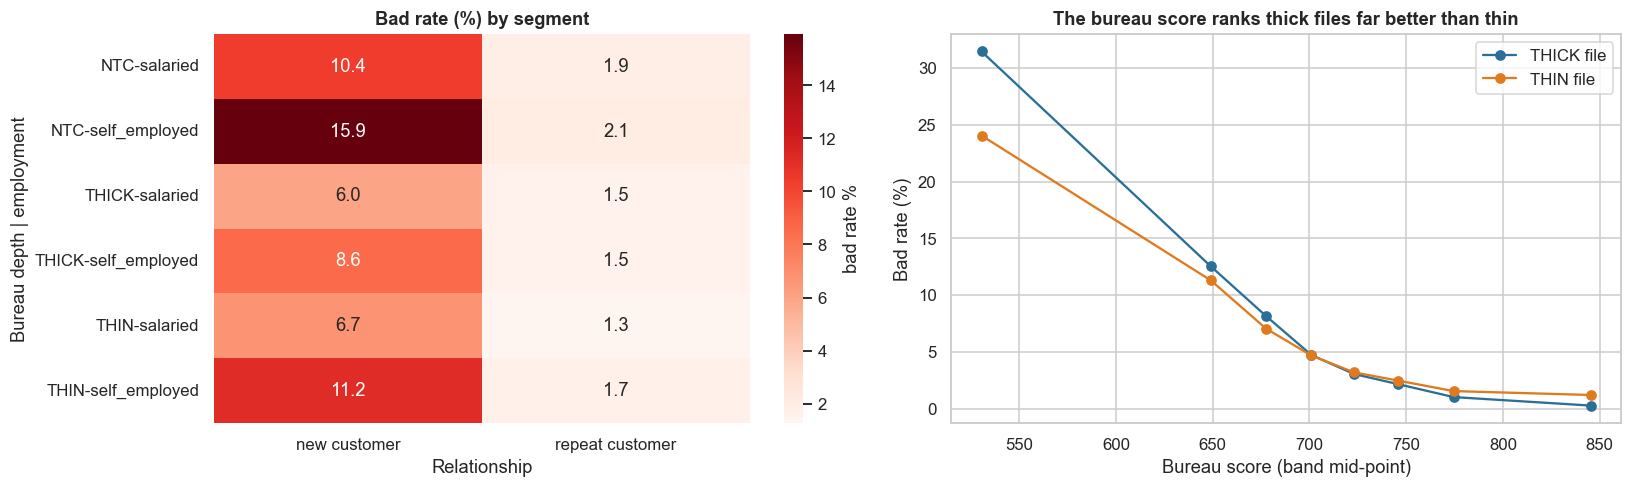

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
hm = df.pivot_table(index=["bureau_depth", "employment"], columns="repeat_customer", values="bad_60dpd_6m", aggfunc="mean") * 100
hm.columns = ["new customer", "repeat customer"]
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", ax=axes[0], cbar_kws={"label": "bad rate %"}); axes[0].set_title("Bad rate (%) by segment"); axes[0].set_xlabel("Relationship"); axes[0].set_ylabel("Bureau depth | employment")
nb = df[(df.repeat_customer == 0) & df.bureau_score.notna()].copy(); nb["band"] = pd.qcut(nb.bureau_score, 8, duplicates="drop")
for dpt, c_ in (("THICK", "#2a6f97"), ("THIN", "#e07a1f")):
    g = nb[nb.bureau_depth == dpt].groupby("band").bad_60dpd_6m.mean() * 100
    axes[1].plot([iv.mid for iv in g.index], g.values, "o-", color=c_, label=f"{dpt} file")
axes[1].set_xlabel("Bureau score (band mid-point)"); axes[1].set_ylabel("Bad rate (%)"); axes[1].set_title("The bureau score ranks thick files far better than thin"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** **left:** bad rates differ hugely by segment: **16% for new-to-credit self-employed new customers vs 1.3% for thin-file salaried repeat customers**. Repeat customers are 4–8× safer in every bureau group. **Right:** among bureau-tested new customers, the bureau score ranks thick files much more steeply than thin files: the same score means less when based on one or two tradelines. Both patterns are the documented motivation for segment-specific underwriting.

## 7. Statistical Analysis (core section)

### 7.1 Do the drivers of default differ by segment? (likelihood-ratio test)

**(a) Why?** Segmentation is justified only if **the relationship between features and default differs** across segments, not merely the average bad rate (a global model handles that with a segment dummy). We compare, on training loans:
- **M_global:** logistic regression with all features + segment dummies.
- **M_interact:** M_global + segment × feature interactions for the 6 key drivers.

The **LR test** is a multi-group Chow test. We also show per-segment coefficients for two drivers with 95% CIs.
**(b) Assumptions:** logit link, independent loans, n per segment ≫ parameters (smallest new-customer segment: ≈ 6,000 loans).

In [7]:
tr = df[TR & (df.repeat_customer == 0).values].copy()                             # new customers (repeat handled separately)
tr["zb"] = ((tr.bureau_score - 720) / 60).fillna(0); tr["lbal"] = np.log(tr.avg_bal_to_income); tr["gst"] = tr.gst_consistency.fillna(0.65)
tr["bnc"] = tr.bounces_6m.clip(upper=4); tr["dpd"] = tr.dpd30_last12m.clip(upper=4)
base_f = "bad_60dpd_6m ~ C(bureau_depth) * C(employment) + zb + dpd + bnc + lbal + inflow_volatility + gst + digital_footprint_score + enquiries_3m + emi_to_income + C(city_tier) + C(product)"
m0 = smf.logit(base_f, data=tr).fit(disp=0)
tr["thick"] = (tr.bureau_depth == "THICK").astype(int)          # bureau terms are zero for NTC, so depth interactions use a thick-file indicator
inter = " + ".join([f"C(bureau_depth):{v}" for v in ["bnc", "lbal", "inflow_volatility", "digital_footprint_score"]] +
                   [f"C(employment):{v}" for v in ["zb", "dpd", "bnc", "lbal", "inflow_volatility", "digital_footprint_score"]] + ["thick:zb", "thick:dpd"])
m1 = smf.logit(base_f + " + " + inter, data=tr).fit(disp=0)
LR = 2 * (m1.llf - m0.llf); dfree = int(m1.df_model - m0.df_model)
print(f"LR test (segment-specific drivers vs common drivers): χ² = {LR:.1f}, df = {dfree}, p = {stats.chi2.sf(LR, dfree):.2g} | AIC {m0.aic:,.0f} → {m1.aic:,.0f}")
rows = []
for dpt in ["NTC", "THIN", "THICK"]:
    for emp in ["salaried", "self_employed"]:
        s_ = tr[(tr.bureau_depth == dpt) & (tr.employment == emp)]
        f_ = "bad_60dpd_6m ~ bnc + lbal + inflow_volatility + digital_footprint_score + emi_to_income" + (" + zb + dpd" if dpt != "NTC" else "")
        mm = smf.logit(f_, data=s_).fit(disp=0); ci = mm.conf_int()
        for v in ["zb", "bnc", "inflow_volatility"]:
            if v in mm.params: rows.append((f"{dpt}|{emp[:4]}", v, mm.params[v], ci.loc[v, 0], ci.loc[v, 1], len(s_), int(s_.bad_60dpd_6m.sum())))
coef = pd.DataFrame(rows, columns=["segment (new customers)", "driver", "coef (log-odds)", "CI low", "CI high", "n", "bads"]).pivot_table(index="segment (new customers)", columns="driver", values="coef (log-odds)")
coef.columns = ["bounces (per bounce)", "inflow volatility", "bureau score (per 60 pts)"]
coef.round(3)

LR test (segment-specific drivers vs common drivers): χ² = 1168.0, df = 16, p = 1.1e-238 | AIC 34,192 → 33,055


,bounces (per bounce),inflow volatility,bureau score (per 60 pts)
segment (new customers),,,
NTC|sala,0.8710,0.7120,NaN
NTC|self,0.9070,1.7480,NaN
THICK|sala,0.0610,0.6090,-1.1020
THICK|self,-0.0320,1.5040,-1.1850
THIN|sala,0.5900,0.3700,-0.5900
THIN|self,0.6230,1.4430,-0.6310


**(c)/(f) Observation:** - **The drivers clearly differ:** adding segment-specific slopes for six drivers improves the fit enormously (LR χ² = 1,168, df = 16, p ≈ 1e-238; AIC 34,192 → 33,055).
- **Bureau score** (log-odds per +60 points): about **−1.1 for thick files vs −0.6 for thin files**, so twice as informative for thick files.
- **Bounces:** about +0.9 log-odds per bounce for NTC, +0.6 for thin files, **≈ 0 for thick files**. Bank-statement data matters precisely where the bureau is silent.
- **Income volatility:** 1.4–1.7 for the self-employed vs 0.4–0.7 for the salaried.
- **(f) Business meaning:** H1 is rejected. One set of weights does not fit everyone, which justifies *some* segmentation. Whether separate *models* beat one flexible model is the next question.

### 7.2 Global vs segmented models, out-of-time

**(a) Why?** The decision is between building and maintaining **one model or twelve**. We compare five scorers on months 10–12:
1. **Bureau score only.** Exists only for thin/thick files; NTC applicants get the median, i.e., no information.
2. **Global logistic** with segment dummies.
3. **Global gradient boosting** with segment variables, which can learn interactions by itself.
4. **12 segmented logistic models.**
5. **12 segmented gradient-boosting models.**

AUC with **DeLong** (Holm over the comparisons vs the global logistic), Gini, KS, and the documented **top/bottom decile bad-rate ratio** with bootstrap CIs.

In [8]:
FEAT = ["bureau_score", "bureau_nohit", "n_tradelines", "dpd30_last12m", "enquiries_3m", "inflow_volatility", "bounces_6m", "avg_bal_to_income", "gst_consistency",
        "digital_footprint_score", "loan_amount", "emi_to_income", "monthly_income", "income_missing", "age", "city_tier", "prior_loans", "prior_max_dpd"]
SEGV = ["is_ntc", "is_thin", "is_se", "repeat_customer", "is_pl"]
df["is_ntc"] = (df.bureau_depth == "NTC").astype(int); df["is_thin"] = (df.bureau_depth == "THIN").astype(int); df["is_se"] = (df.employment == "self_employed").astype(int)
df["is_pl"] = (df["product"] == "personal_loan").astype(int)
def lin_X(d):
    X = d[FEAT + SEGV].copy(); X["bureau_score"] = X.bureau_score.fillna(720); X["gst_consistency"] = X.gst_consistency.fillna(0.65); X["prior_max_dpd"] = X.prior_max_dpd.fillna(0)
    for c in ["avg_bal_to_income", "loan_amount", "monthly_income"]: X[c] = np.log(X[c])
    X["bounces_6m"] = X.bounces_6m.clip(upper=6); X["dpd30_last12m"] = X.dpd30_last12m.clip(upper=6)
    return X
def logit(): return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
def hgb(): return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
y = df.bad_60dpd_6m.values; yte = y[TE]; XL = lin_X(df); XH = df[FEAT + SEGV]
P = {"1 bureau score only": -df.bureau_score.fillna(df.bureau_score.median()).values[TE]}
P["2 global logistic"] = logit().fit(XL[TR], y[TR]).predict_proba(XL[TE])[:, 1]
P["3 global gradient boosting"] = hgb().fit(XH[TR], y[TR]).predict_proba(XH[TE])[:, 1]
def segmented(make, X, key="segment", rows_tr=TR, rows_te=TE):
    out = np.zeros(rows_te.sum()); seg_te = df[key].values[rows_te]
    for s_ in np.unique(df[key].values[rows_tr]):
        mtr = rows_tr & (df[key].values == s_); mte = seg_te == s_
        if mte.sum() == 0: continue
        if y[mtr].sum() < 10 or (1 - y[mtr]).sum() < 10: out[mte] = y[mtr].mean(); continue
        out[mte] = make().fit(X[mtr], y[mtr]).predict_proba(X[rows_te][mte])[:, 1]
    return out
P["4 segmented logistic (12)"] = segmented(logit, XL); P["5 segmented gradient boosting (12)"] = segmented(hgb, XH)
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
def ks(y, p): o = np.argsort(-p); yy = y[o]; return np.max(np.abs(np.cumsum(yy) / yy.sum() - np.cumsum(1 - yy) / (1 - yy).sum()))
def topbot(y, p, q=10):
    b = pd.qcut(rankdata(p, method="ordinal"), q, labels=False); g = pd.Series(y).groupby(b).mean(); return g.iloc[-1] / g.iloc[0] if g.iloc[0] > 0 else np.inf
names = list(P); A_, C_ = delong(yte, np.vstack([P[n] for n in names]))
mt = pd.DataFrame({"AUC": A_, "Gini": 2 * A_ - 1, "KS": [ks(yte, P[n]) for n in names], "top/bottom decile bad-rate ratio": [topbot(yte, P[n]) for n in names]}, index=names)
ref = names.index("2 global logistic"); pv = [2 * stats.norm.sf(abs(A_[i] - A_[ref]) / np.sqrt(C_[i, i] + C_[ref, ref] - 2 * C_[i, ref])) if i != ref else np.nan for i in range(len(names))]
mt["Δ AUC vs global logistic"] = A_ - A_[ref]; mt["DeLong p"] = pv
mask = ~np.isnan(pv); mt.loc[np.array(names)[mask], "p_holm"] = multipletests(np.array(pv)[mask], method="holm")[1]
bs = {n: [] for n in names}
for _ in range(500):
    i = RNG.integers(0, len(yte), len(yte))
    for n in names: bs[n].append(topbot(yte[i], P[n][i]))
mt["ratio CI low"] = [np.percentile(bs[n], 2.5) for n in names]; mt["ratio CI high"] = [np.percentile(bs[n], 97.5) for n in names]
mt.round(4)

,AUC,Gini,KS,top/bottom decile bad-rate ratio,Δ AUC vs global logistic,DeLong p,p_holm,ratio CI low,ratio CI high
1 bureau score only,0.6778,0.3555,0.2790,24.5333,-0.1690,0.0000,0.0000,16.6102,47.5406
2 global logistic,0.8468,0.6936,0.5445,56.0833,0.0000,NaN,NaN,35.6458,134.8600
3 global gradient boosting,0.8542,0.7083,0.5554,62.1818,0.0074,0.0001,0.0002,37.6270,170.1812
4 segmented logistic (12),0.8566,0.7133,0.5547,70.3000,0.0099,0.0000,0.0000,41.6354,173.5250
5 segmented gradient boosting (12),0.8339,0.6678,0.5311,48.2143,-0.0129,0.0007,0.0007,30.4955,85.2156


**(c)/(f) Observation:** - **The bureau score alone is weak overall** (AUC 0.678, KS 0.28), mainly because it cannot rank the 30% of applicants who are new to credit.
- **The global logistic** with segment dummies reaches **0.847**.
- **Global gradient boosting** (0.854, +0.007, Holm p = 0.0002) and **12 segmented logistic models** (0.857, +0.010, p < 0.0001) both improve on it significantly. Their gap to each other (0.002) is negligible.
- **12 segmented gradient-boosting models are significantly *worse*** (0.834, −0.013, p = 0.0007): each segment's trees over-fit too few defaults.
- **Top/bottom decile bad-rate ratios** are 24.5× for the bureau and 56–70× for the models, but with very wide bootstrap CIs (e.g., 42–174 for the best model), because the safest decile has very few defaults.
- **(f) Business meaning:** segmenting a *simple* model helps. Segmenting a *flexible* model hurts. A flexible global model gets the same benefit without twelve models to maintain.

### 7.3 Within-segment performance: where does segmentation help?

Pooled AUC mixes two things: ranking *across* segments (easy, since segments have different bad rates) and ranking *within* a segment (hard, and what matters when a segment has its own cut-off). We report AUC **within each of the 12 segments** for the global and segmented gradient-boosting models (DeLong per segment, BH across segments).

In [9]:
seg_te = df.segment.values[TE]; rows = []
for s_ in sorted(np.unique(seg_te)):
    m = seg_te == s_; ys = yte[m]
    if ys.sum() < 15: continue
    a_, c_ = delong(ys, np.vstack([P["3 global gradient boosting"][m], P["5 segmented gradient boosting (12)"][m], P["2 global logistic"][m], P["4 segmented logistic (12)"][m]]))
    d = a_[1] - a_[0]; se = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1]); d2 = a_[3] - a_[2]; se2 = np.sqrt(c_[2, 2] + c_[3, 3] - 2 * c_[2, 3])
    rows.append((s_, int(m.sum()), int(ys.sum()), int(y[TR & (df.segment.values == s_)].sum()), a_[2], a_[3], d2, 2 * stats.norm.sf(abs(d2) / se2), a_[0], a_[1], d, 2 * stats.norm.sf(abs(d) / se)))
ws = pd.DataFrame(rows, columns=["segment", "test n", "test bads", "train bads", "AUC global logit", "AUC segmented logit", "Δ logit", "p logit", "AUC global GBM", "AUC segmented GBM", "Δ GBM", "p GBM"]).set_index("segment")
ws["q_BH logit"] = multipletests(ws["p logit"], method="fdr_bh")[1]; ws["q_BH GBM"] = multipletests(ws["p GBM"], method="fdr_bh")[1]
ws.round(4)

,test n,test bads,train bads,AUC global logit,AUC segmented logit,Δ logit,p logit,AUC global GBM,AUC segmented GBM,Δ GBM,p GBM,q_BH logit,q_BH GBM
segment,,,,,,,,,,,,,
NTC|sala|new,2504,283,1391,0.7801,0.7907,0.0105,0.0036,0.7844,0.7772,-0.0073,0.1169,0.0164,0.2104
NTC|sala|repeat,1227,21,97,0.7839,0.7326,-0.0513,0.0290,0.7503,0.4787,-0.2717,0.0000,0.0869,0.0001
NTC|self|new,1572,255,1340,0.8345,0.8375,0.0029,0.3684,0.8333,0.8128,-0.0205,0.0058,0.4610,0.0263
THICK|sala|new,3757,231,1221,0.8186,0.8399,0.0213,0.0004,0.8329,0.8318,-0.0011,0.7787,0.0038,0.7787
THICK|sala|repeat,1751,26,114,0.7178,0.6965,-0.0212,0.4098,0.7034,0.6390,-0.0644,0.1827,0.4610,0.2740
THICK|self|new,2368,203,1071,0.8410,0.8525,0.0115,0.0391,0.8490,0.8452,-0.0038,0.4607,0.0881,0.5183
THICK|self|repeat,1110,18,70,0.6937,0.8021,0.1084,0.0500,0.6917,0.5898,-0.1020,0.2813,0.0899,0.3617
THIN|sala|new,2083,144,758,0.8071,0.8069,-0.0002,0.9755,0.8064,0.7903,-0.0160,0.0569,0.9755,0.1281
THIN|self|new,1201,123,784,0.8696,0.8727,0.0030,0.3987,0.8720,0.8449,-0.0271,0.0101,0.4610,0.0303


**Observation:** within segments (BH-adjusted), segmented logistic models help significantly in the two largest new-customer segments: **THICK|salaried (+0.021, q = 0.004)** and **NTC|salaried (+0.011, q = 0.016)**. They are not better elsewhere, and are *worse* for **NTC|salaried repeat** customers (−0.051, q = 0.087), a segment with only 97 training defaults. Segmented gradient boosting collapses there: **AUC 0.48, worse than random** (q = 0.0001). **Business meaning:** segment models earn their keep only in large segments with clearly different drivers. Small segments should borrow strength from a pooled model.

### 7.4 How many sub-models? The fragmentation sweep

We split the book into ever finer segments: 1, 2 (new/repeat), 3 (bureau depth), 6 (+ employment), 12 (+ new/repeat), 24 (+ product) and 72 (+ city tier: beyond Kissht's "39"). We fit one **logistic** sub-model per segment (logistic because it is what most model-risk teams validate per segment). For each split we report the out-of-time AUC and log loss, the **events per variable** (bads per parameter) in the smallest segment, and the number of segments below the common EPV ≥ 10 rule. Bootstrap CIs for AUC.

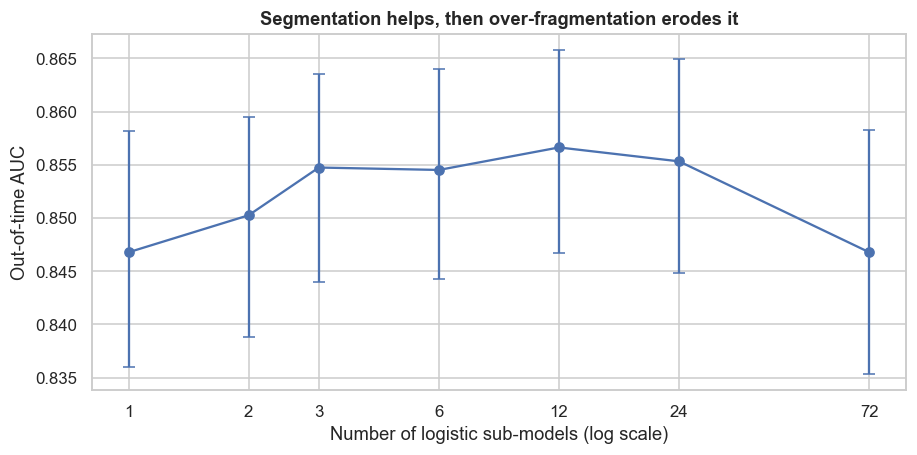

,segments,AUC,CI low,CI high,log loss,fewest train bads in a segment,min EPV,segments with EPV < 10
split,,,,,,,,
1,1,0.8468,0.8360,0.8581,0.1863,7012,292.1667,0
2,2,0.8503,0.8388,0.8595,0.1834,447,18.6250,0
3,3,0.8547,0.8440,0.8636,0.1813,1641,68.3750,0
6,6,0.8545,0.8442,0.8640,0.1815,810,33.7500,0
12,12,0.8566,0.8467,0.8658,0.1792,47,1.9583,6
24,24,0.8553,0.8449,0.8649,0.1797,20,0.8333,12
72,72,0.8468,0.8353,0.8583,0.1835,3,0.1250,66


In [10]:
df["seg2"] = np.where(df.repeat_customer == 1, "repeat", "new"); df["seg3"] = df.bureau_depth; df["seg6"] = df.bureau_depth + "|" + df.employment
df["seg12"] = df.segment; df["seg24"] = df.segment + "|" + df["product"]; df["seg72"] = df.seg24 + "|T" + df.city_tier.astype(str); df["seg1"] = "all"
from sklearn.metrics import log_loss
sw = []; NPAR = XL.shape[1] + 1
for key in ["seg1", "seg2", "seg3", "seg6", "seg12", "seg24", "seg72"]:
    p_ = np.clip(segmented(logit, XL, key=key), 1e-4, 1 - 1e-4); a = roc_auc_score(yte, p_)
    bads = df[TR].groupby(key).bad_60dpd_6m.sum()
    bsa = [roc_auc_score(yte[i], p_[i]) for i in (RNG.integers(0, len(yte), len(yte)) for _ in range(200))]
    sw.append((int(key[3:]), df[key].nunique(), a, np.percentile(bsa, 2.5), np.percentile(bsa, 97.5), log_loss(yte, p_), int(bads.min()), bads.min() / NPAR, int((bads / NPAR < 10).sum())))
sw = pd.DataFrame(sw, columns=["split", "segments", "AUC", "CI low", "CI high", "log loss", "fewest train bads in a segment", "min EPV", "segments with EPV < 10"]).set_index("split")
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.errorbar(sw.segments, sw.AUC, yerr=[sw.AUC - sw["CI low"], sw["CI high"] - sw.AUC], fmt="o-", capsize=4)
ax.set_xscale("log"); ax.set_xticks(sw.segments); ax.set_xticklabels(sw.segments); ax.set_xlabel("Number of logistic sub-models (log scale)"); ax.set_ylabel("Out-of-time AUC")
ax.set_title("Segmentation helps, then over-fragmentation erodes it"); plt.tight_layout(); plt.show()
sw.round(4)

**Takeaway:** AUC rises from **0.847 (1 model) to 0.850 (2) and 0.855 (3–6), peaks at 0.857 with 12 segments**, then falls to 0.855 (24) and back to **0.847 with 72 segments**. The bootstrap CIs overlap throughout, so the gains of segmentation are modest even at the peak. The decline is explained by **events per variable**: at 12 segments the smallest has 47 training defaults (EPV 2.0, with 6 segments below the EPV ≥ 10 rule), and at 72 segments the smallest has **3 defaults** and 66 of 72 segments are below the rule. Log loss tells the same story (best 0.179 at 12). **Business meaning:** the right number of sub-models depends on **defaults per segment, not customer types**. With this book's ~7,000 training defaults, about 6–12 segments is the ceiling; "39" would need a book several times larger.

### 7.5 Is "5.17× vs 2.13×" a fair comparison? The top/bottom ratio under different definitions

The top/bottom bad-rate ratio is easy to explain, but it **depends on how many buckets you use and on who is in the population**. We compute it for the best model and the bureau score under deciles, quintiles and ventiles, and on two populations: all loans, and bureau-tested loans only (where the bureau score exists).

In [11]:
best_name = mt.AUC.idxmax(); pb = P[best_name]; bur = P["1 bureau score only"]; bt = (df.bureau_depth != "NTC").values[TE]
rr = []
for q, lab in ((5, "quintiles"), (10, "deciles"), (20, "ventiles")):
    rr.append((lab, topbot(yte, pb, q), topbot(yte, bur, q), topbot(yte[bt], pb[bt], q), topbot(yte[bt], bur[bt], q)))
rr = pd.DataFrame(rr, columns=["buckets", f"best model, all loans", "bureau score, all loans", "best model, bureau-tested only", "bureau score, bureau-tested only"]).set_index("buckets")
print(f"Best model = {best_name}")
rr.round(2)

Best model = 4 segmented logistic (12)


,"best model, all loans","bureau score, all loans","best model, bureau-tested only","bureau score, bureau-tested only"
buckets,,,,
quintiles,36.1500,12.7300,32.1200,19.2200
deciles,70.3000,24.5300,68.6700,43.4300
ventiles,246.5000,41.8300,inf,98.0000


**Observation:** for the same best model, the top/bottom ratio is **36× with quintiles, 70× with deciles and infinite with ventiles** (the safest twentieth had no defaults among bureau-tested loans). The bureau score's decile ratio is **24.5× on all loans but 43× on bureau-tested loans only**: excluding the NTC applicants it cannot score flatters it. So "5.17× vs 2.13×" depends entirely on how many buckets were used and who was included. The documented numbers are plausible for coarse buckets but **cannot be compared with each other, or with other lenders, without the definition**. **Business meaning:** report a top/bottom ratio only with its bucket count and population, and always alongside Gini/KS and approval rate at a fixed loss rate.

### 7.6 Calibration within segments: does a global model mis-price some customers?

A global model can rank well overall yet **systematically over- or under-predict** for a segment. That mis-prices loans and distorts segment cut-offs. For each segment we test calibration-in-the-large (observed − predicted bad rate) with a z-test, using Holm across 12 segments, for the global logistic and the best model.

In [12]:
cal = []
for s_ in sorted(np.unique(seg_te)):
    m = seg_te == s_; ys = yte[m]; row = [s_, int(m.sum()), ys.mean()]
    for nm in ["2 global logistic", best_name]:
        pp = P[nm][m]; diff = ys.mean() - pp.mean(); se = np.sqrt((pp * (1 - pp)).sum()) / m.sum()
        row += [pp.mean(), diff * 100, 2 * stats.norm.sf(abs(diff) / se)]
    cal.append(row)
cal = pd.DataFrame(cal, columns=["segment", "n", "observed", "pred global", "obs − pred global (pp)", "p global", "pred best", "obs − pred best (pp)", "p best"]).set_index("segment")
cal["p_holm global"] = multipletests(cal["p global"], method="holm")[1]; cal["p_holm best"] = multipletests(cal["p best"], method="holm")[1]
print(f"Mean absolute calibration error across segments: global {cal['obs − pred global (pp)'].abs().mean():.2f} pp vs best {cal['obs − pred best (pp)'].abs().mean():.2f} pp")
cal.round(4)

Mean absolute calibration error across segments: global 0.51 pp vs best 0.42 pp


,n,observed,pred global,obs − pred global (pp),p global,pred best,obs − pred best (pp),p best,p_holm global,p_holm best
segment,,,,,,,,,,
NTC|sala|new,2504,0.1130,0.1088,0.4254,0.4795,0.1080,0.5033,0.3698,1.0000,1.0000
NTC|sala|repeat,1227,0.0171,0.0182,-0.1056,0.7745,0.0201,-0.2964,0.4481,1.0000,1.0000
NTC|self|new,1572,0.1622,0.1552,0.6967,0.4105,0.1601,0.2140,0.7808,1.0000,1.0000
NTC|self|repeat,710,0.0169,0.0297,-1.2760,0.0338,0.0226,-0.5679,0.2911,0.3828,1.0000
THICK|sala|new,3757,0.0615,0.0579,0.3623,0.3010,0.0598,0.1692,0.6325,1.0000,1.0000
THICK|sala|repeat,1751,0.0148,0.0108,0.4091,0.0760,0.0148,0.0021,0.9941,0.7602,1.0000
THICK|self|new,2368,0.0857,0.0894,-0.3646,0.4741,0.0816,0.4122,0.3960,1.0000,1.0000
THICK|self|repeat,1110,0.0162,0.0200,-0.3802,0.2979,0.0152,0.0991,0.7822,1.0000,1.0000
THIN|sala|new,2083,0.0691,0.0686,0.0546,0.9148,0.0651,0.4033,0.4190,1.0000,1.0000


**Observation:** both models are well calibrated within segments: **no segment shows a Holm-significant gap** between predicted and observed bad rates. The mean absolute error is **0.51 pp for the global logistic vs 0.42 pp for the segmented model**, both under the 1 pp guardrail. The global model over-predicts the small **repeat** segments by about 1.1–1.3 pp (unadjusted p ≈ 0.03), which would slightly *under-approve* good repeat customers. The segmented model halves that error. **Business meaning:** calibration is a modest but real benefit of segment-level models for small, very safe segments, or a reason to recalibrate a global model per segment.

### 7.7 Rank ordering and stability: monotonic deciles and population shift

Two checks every model-risk team requires:
1. **Monotonic rank ordering:** bad rate should rise steadily across score deciles. Tested with the **Cochran–Armitage trend test** and a count of decile reversals.
2. **Population stability:** the share of repeat customers grows over the year. The **PSI** of the score between training and test (overall and by segment) tells us whether the model is being applied to a different population (PSI < 0.1 stable; 0.1–0.25 watch; > 0.25 act).

In [13]:
dec = pd.qcut(rankdata(pb, method="ordinal"), 10, labels=False); g = pd.DataFrame({"d": dec, "y": yte}).groupby("d").y.agg(["sum", "size"]); g["bad rate"] = g["sum"] / g["size"]
xbar = (g.index * g["size"]).sum() / g["size"].sum(); pbar = g["sum"].sum() / g["size"].sum()
T = (g.index.values * (g["sum"] - g["size"] * pbar)).sum(); V = pbar * (1 - pbar) * ((g["size"] * (g.index.values - xbar) ** 2).sum())
print(f"Cochran–Armitage trend: z = {T / np.sqrt(V):.1f}, p = {2 * stats.norm.sf(abs(T / np.sqrt(V))):.2g}; decile reversals = {(np.diff(g['bad rate']) < 0).sum()}")
p_tr_best = (hgb().fit(XH[TR], y[TR]).predict_proba(XH[TR])[:, 1] if best_name.startswith("3") else segmented(hgb, XH, rows_te=TR) if best_name.startswith("5") else
             logit().fit(XL[TR], y[TR]).predict_proba(XL[TR])[:, 1] if best_name.startswith("2") else segmented(logit, XL, rows_te=TR))
def psi(a, b, q=10):
    e = np.quantile(a, np.linspace(0, 1, q + 1)); e[0], e[-1] = -np.inf, np.inf
    pa = np.histogram(a, e)[0] / len(a) + 1e-6; pbb = np.histogram(b, e)[0] / len(b) + 1e-6; return ((pa - pbb) * np.log(pa / pbb)).sum()
ps = {"overall": psi(p_tr_best, pb)}
for s_ in ["new", "repeat"]:
    ps[f"{s_} customers"] = psi(p_tr_best[df.seg2.values[TR] == s_], pb[df.seg2.values[TE] == s_])
print(f"Repeat-customer share: train {df.repeat_customer[TR].mean():.1%} → test {df.repeat_customer[TE].mean():.1%}")
print("PSI of the score (train → test):", {k: round(v, 3) for k, v in ps.items()})
g.round(4)

Cochran–Armitage trend: z = 42.6, p = 0; decile reversals = 1


Repeat-customer share: train 26.8% → test 32.4%
PSI of the score (train → test): {'overall': np.float64(0.003), 'new customers': np.float64(0.001), 'repeat customers': np.float64(0.002)}


,sum,size,bad rate
d,,,
0,10,1995,0.0050
1,16,1995,0.0080
2,13,1995,0.0065
3,28,1994,0.0140
4,39,1995,0.0195
5,58,1995,0.0291
6,88,1994,0.0441
7,145,1995,0.0727
8,237,1995,0.1188


**Observation:** - **Rank ordering is strong:** the bad rate rises from 0.5% in the safest decile to **35.2% in the riskiest** (Cochran–Armitage z = 42.6). There is **one small reversal** at the very top (decile 2 at 0.80% vs decile 3 at 0.65%), within noise at 10–16 defaults each.
- **Stability:** the repeat-customer share grows from 26.8% to 32.4%, but the score's **PSI is only 0.003** overall (and ≤ 0.002 within new and repeat customers), well under the 0.1 warning level. The model is scored on a population it knows; the mix shift changes the portfolio bad rate, not the score's validity.

## 8. ML Section — brief

- **Gradient boosting** is the main model, with no tuning (per the brief). It is compared with logistic regression, the model-risk-friendly benchmark that most segment scorecards still use.
- **What a global tree model does:** splitting on `is_ntc`, `repeat_customer` and `is_se` first, it effectively builds its own segments and segment-specific interactions, which is why "one GBM" competes with "many logistic models" (7.2–7.4).
- **Repeat customers** get their own treatment in every approach because their own repayment history (prior max DPD) dominates. This matches the documented 26.46% decline rate for repeat applicants.

## 9. Business Translation — more approvals at the same loss rate

Booked-loan data show who defaults among approved customers. As a **business proxy** (D-14-07), we ask: if each test-period applicant were scored, how many could we approve while keeping the **approved book's bad rate ≤ 3%**? More approvals at the same risk is the direct business value of better ranking. Each extra good loan earns ≈ ₹2,800 (interest + fees net of funding over the tenure); each extra bad loan loses 75% of the ticket.

In [14]:
TARGET = 0.03; MARGIN, LGD = 2800, 0.75; amt = df.loan_amount.values[TE]
def approve_at_target(p):
    o = np.argsort(p); cum_bad = np.cumsum(yte[o]) / np.arange(1, len(o) + 1); k = np.where(cum_bad <= TARGET)[0]
    k = k.max() + 1 if len(k) else 0; sel = o[:k]; return k / len(o), yte[sel].mean() if k else np.nan, ((1 - yte[sel]) * MARGIN - yte[sel] * LGD * amt[sel]).sum()
ap = pd.DataFrame([(n, *approve_at_target(P[n])) for n in names], columns=["model", "approval rate at ≤ 3% bad", "bad rate of approved", "₹ profit on approved (test, 3 months)"]).set_index("model")
ap["extra approvals vs global logistic (pp)"] = (ap.iloc[:, 0] - ap.loc["2 global logistic"].iloc[0]) * 100
ap["₹ crore / year vs global logistic (per 1 lakh applicants/month)"] = (ap.iloc[:, 2] - ap.loc["2 global logistic"].iloc[2]) / TE.sum() * 1e5 * 12 / 1e7
ap.round(4)

,approval rate at ≤ 3% bad,bad rate of approved,"₹ profit on approved (test, 3 months)",extra approvals vs global logistic (pp),₹ crore / year vs global logistic (per 1 lakh applicants/month)
model,,,,,
1 bureau score only,0.4084,0.0299,"17,839,000.0000",-44.0345,-115.0150
2 global logistic,0.8488,0.0299,"36,958,325.0000",0.0000,0.0000
3 global gradient boosting,0.8617,0.0300,"37,482,000.0000",1.2934,3.1502
4 segmented logistic (12),0.8596,0.0300,"37,488,575.0000",1.0878,3.1898
5 segmented gradient boosting (12),0.8346,0.0300,"36,380,800.0000",-1.4137,-3.4742


**Takeaway (business reading):** at a portfolio bad-rate target of **3%**:
- **Approval rates:** global logistic **84.9%**; global gradient boosting **86.2%** (+1.3 pp); segmented logistic **86.0%** (+1.1 pp); segmented gradient boosting only 83.5% (−1.4 pp); **bureau score alone 40.8%**.
- **₹ value (per 1 lakh applicants a month):** the two best models earn ≈ **₹3.2 crore/year more** than the global logistic at the same loss rate. Over-segmented boosting would lose ≈ ₹3.5 crore/year. Relying on the bureau alone would forgo ≈ **₹115 crore/year**, mostly by declining NTC applicants it cannot score.
- **Reading:** the real ₹ comes from **using bank-statement and segment information at all**. The choice between "1 flexible model" and "12 simple ones" is worth little in ₹, but a lot in maintenance and validation cost.
- Assumptions: ₹2,800 margin per good loan, 75% LGD; booked-loan data are used as a proxy for applicants.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** drivers differ by segment.
- **H2 ✅:** segmented logistic and global boosting both beat the global logistic, and tie each other; segmented boosting is worse.
- **H3:** past ~12 segments performance declines.
- **H4 ✅:** calibration is acceptable for both.
- **Guardrail met:** calibration error ≤ 1 pp per segment.

**I recommend:**
1. **Production model:** one **global gradient-boosting model** with segment variables (bureau depth, employment, repeat), **plus a separate repeat-customer model** driven by the lender's own repayment history. That is 2 models instead of 39, with equal ranking power.
2. **If model risk requires scorecards:** use **6–12 logistic segments at most**, merging any segment with fewer than ~10 defaults per parameter into its parent.
3. **Calibrate per segment:** monitor predicted vs observed bad rate by segment monthly, and recalibrate the global model for small safe segments (repeat customers).
4. **Report properly:** Gini/KS and approval rate at a fixed loss rate. Quote any top/bottom ratio only with its bucket count and population.
5. **Never rely on the bureau alone** for NTC/thin files: bank-statement features (bounces, balances) are where the information is.

**KPIs:** out-of-time Gini per segment; approval rate at target loss; calibration error per segment; PSI per segment; number of segments below EPV 10; share of offers within 10 minutes (documented ≈ 85%).

## 11. Risks, Limitations and Next Steps

- **Synthetic drivers:** we built segment-specific drivers into the data, so heterogeneity is guaranteed here. On real data, test it first (7.1) before building sub-models.
- **Booked-loan bias:** we only see the outcomes of approved loans, so the approval-rate analysis is a proxy. Reject inference (Case 13) or a small random-approval holdout is needed for real cut-off setting.
- **Model risk and governance:** every sub-model needs development documentation, validation, monitoring and annual review (RBI's model-risk expectations for regulated entities and their lending partners). 39 models carry roughly 39 times the governance load.
- **Mix shift:** the repeat share grows (PSI in 7.7). Monitor PSI per segment monthly and recalibrate when it exceeds 0.1.
- **Metric hygiene:** never compare top/bottom ratios across different bucket definitions or populations (7.5). Pair them with Gini/KS and approval rate at fixed loss.

## 12. Appendix

| Quantity | Formula |
|---|---|
| LR (Chow-type) test | LR = 2(ℓ_interact − ℓ_global) ~ χ²(df = extra parameters) |
| Gini, KS | Gini = 2·AUC − 1; KS = max |F_bad(s) − F_good(s)| |
| Top/bottom ratio | bad rate(riskiest bucket) / bad rate(safest bucket) |
| Events per variable | EPV = bads / model parameters (rule of thumb ≥ 10) |
| Cochran–Armitage | z = Σ xᵢ(bᵢ − nᵢp̄) / √(p̄(1−p̄) Σ nᵢ(xᵢ − x̄)²) |
| PSI | Σ (pₐ − p_b) ln(pₐ/p_b) over score bins |
| Approval at target | largest share approved (safest first) with cumulative bad rate ≤ target |

| Term | Meaning |
|---|---|
| NTC / thin / thick file | No bureau record / 1–2 tradelines / established history |
| Segmented model | A separate model for each customer segment |
| Sub-model fragmentation | Too many segments, each with too few defaults to learn from |
| Rank ordering | Riskier scores have higher bad rates |
| GNPA | Gross non-performing assets as a share of the loan book |
| DPD | Days past due |